In [1]:
import numpy as np
import pandas as pd

# Load the pre-cleaned CSV file directly as integers
exp_df = pd.read_csv('Shroud_Exp_by_Skill_Level_Cleaned.csv', header=None, dtype=int)

# Convert the DataFrame column into a NumPy array
exp_by_skill_level = exp_df.values.flatten()

print(exp_by_skill_level[:15])  # Print first 15 elements to verify
print("Total elements:", len(exp_by_skill_level))

[  0  10  21  33  46  60  76  93 112 133 156 181 209 239 272]
Total elements: 200


b_est = 1.10
a_est = 8.02
2 10 10
3 11 11
4 12 12
5 13 13
6 14 14
7 16 16
8 17 17
9 19 19
10 21 21
11 23 23
12 25 25
13 28 28
14 30 30
15 33 33
16 37 37
17 40 41
18 44 45
19 49 49
20 54 54
21 59 59


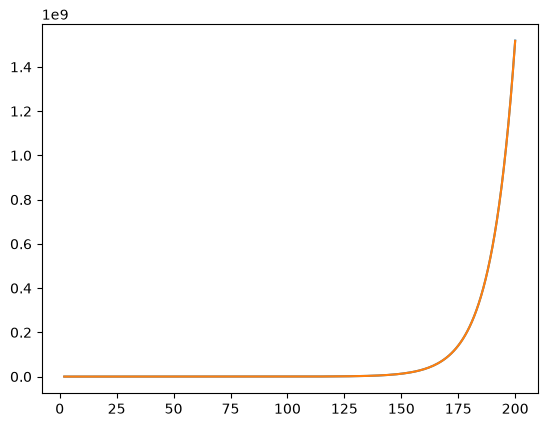

In [2]:
# Fitting the difference in exp values to an exponential function is a
# very close fit, but no cigar!
x = []
diff = []
for i in range(1, len(exp_by_skill_level)):
    x.append(i+1)
    diff.append(exp_by_skill_level[i] - exp_by_skill_level[i-1])
log_y = np.log(diff)
slope, intercept = np.polyfit(x, log_y, 1)

b_est = np.exp(slope)
a_est = np.exp(intercept)

print(f'b_est = {b_est:.2f}')
print(f'a_est = {a_est:.2f}')

import matplotlib.pyplot as plt

x = []
y = []
y_fit = []
for i in range(1, len(exp_by_skill_level)):
    x.append(i+1)
    y.append(exp_by_skill_level[i] - exp_by_skill_level[i-1])
    y_fit.append(int(a_est*b_est**(i+1)+0.5))

for i in range(20):
    print(x[i], y[i], y_fit[i])
plt.plot(x, y)
plt.plot(x, y_fit)

In [3]:
import pandas as pd

# Load the pre-cleaned CSV file
df = pd.read_csv('SkillExp_Adventuring_Skills_Cleaned.csv')

# Assign skills and modifiers directly from the clean columns
skills = df['Skill_Name'].astype(str).str.lower()
modifiers = df['Skill_Multiplier'].astype(int)

skill_modifiers = pd.DataFrame({
    'skill': skills,
    'modifier': modifiers
})

print(skill_modifiers.head())

           skill  modifier
0  bladed combat         1
1         thrust         1
2        riposte         1
3    blade speed         4
4   double slash         1


In [4]:
def calc_skill_exp_at_level(skill, level, exp_by_skill_level, skill_modifiers):
    modifier = 0
    for i in range(len(skill_modifiers)):
        if skill.lower() == skill_modifiers['skill'][i]:
            modifier = skill_modifiers['modifier'][i]
            break
    return int(exp_by_skill_level[level-1] * modifier)

In [5]:
magic_schools = {
    "air"   : ["Air Magic Specialization", "Air's Embrace", "Blink", "Chain Lightning", "Dash", "Discharge", "Earth Warding", "Gust", "Lightning", "Lightning Storm", "Rapid Discharge", "Shield of Air", "Summon Air Elemental", "Well Grounded"],  
    "death" : ["Tap Soul", "Corpse Explosion", "Death Touch", "Death Mastery", "Summon Skeleton", "Death Ray", "Undead Mastery", "Mummified Undead", "Death Shield", "Death Field", "Death Magic Specialization", "Life Warding", "Summon Lich"],
    "earth" : ["Stone Fist", "Root", "Stone Arrow", "Strength of Earth", "Sympathy of Stone", "Shield of Crystal", "Earthquake", "Earth's Embrace", "Bulwark of Earth", "Summon Earth Elemental", "Torpor", "Earth Magic Specialization", "Air Warding"],
    "fire"  : ["Flame Fist", "Fire Arrow", "Ignite Weapon", "Highly Flammable", "Fireball", "Immolation", "Fire Speed", "Fire Proof", "Ring of Fire", "Fire Magic Specialization", "Water Warding", "Summon Fire Elemental"],
    "life"  : ["Healing Touch", "Healing Ray", "Purify", "Beneficent Blessing", "Healing Burst", "Purify Burst", "Banish Undead", "Life Power", "Life Reach", "Healing Grace", "Resurrection", "Life Magic Specialization", "Death Warding", "Healing Blast"],
    "moon"  : ["Night Vision", "Vanish", "Celestial Blessing", "Fireflies", "Animal Charm", "Moon Worship", "Shadow Form", "Cocoon of Night", "Meteor Shower", "Shooting Star", "Moon Beams", "Moon Eater", "Night Step", "Summon Will-O-Wisp", "Lunar Magic Specialization", "Sun Warding"],
    "sun"   : ["Light", "Searing Ray", "Enlightenment", "Blind", "Sun Worship", "Reveal Hidden", "Dazzling Rays", "Sun Eater", "Summon Phoenix", "Elysian Illumination", "Solar Flare", "Sun Magic Specialization", "Moon Warding"],
    "water" : ["Ice Fist", "Ice Arrow", "Douse", "Icy Breath", "Ice Field", "Soothing Rain", "Shield of Ice", "Blue Blooded", "Summon Water Elemental", "Cone of Cold", "Water Magic Specialization", "Fire Warding", "Summon Ice Elemental"]
}

In [6]:
skills_to_optimize = ["Ice Fist", "Ice Arrow", "Douse", "Icy Breath", "Ice Field", "Soothing Rain", "Shield of Ice", "Blue Blooded", "Summon Water Elemental", "Cone of Cold"]
target_attunement = 100

In [7]:
all_skills_in_same_school = False
for school in magic_schools:
    all_skills_found = True
    for i in range(len(skills_to_optimize)):
        if not skills_to_optimize[i] in magic_schools[school]:
            all_skills_found = False
            break
    if all_skills_found:
        all_skills_in_same_school = True
        break
assert all_skills_in_same_school is True, "All skills must belong to the same magic school!"
    
optimization_data = {}
for i in range(len(skills_to_optimize)):
    #optimization_data.append({'skill': skills_to_optimize[i], 'level': target_attunement})
    optimization_data[skills_to_optimize[i]] = target_attunement

finished_optimization = False
while not finished_optimization:
    skill_most_to_gain_from_dropping = None
    max_gain = 0
    skill_least_cost_to_raise = None
    min_cost = float('inf')
    for skill in optimization_data:
        skill_exp_last = calc_skill_exp_at_level(skill, optimization_data[skill]-1, exp_by_skill_level, skill_modifiers)
        skill_exp = calc_skill_exp_at_level(skill, optimization_data[skill], exp_by_skill_level, skill_modifiers)
        skill_exp_next = calc_skill_exp_at_level(skill, optimization_data[skill]+1, exp_by_skill_level, skill_modifiers)

        cost_to_level_up = skill_exp_next - skill_exp
        if cost_to_level_up < min_cost:
            min_cost = cost_to_level_up
            skill_least_cost_to_raise = skill

        gain_from_drop = skill_exp - skill_exp_last
        if gain_from_drop > max_gain:
            max_gain = gain_from_drop
            skill_most_to_gain_from_dropping = skill

    if max_gain < min_cost:
        finished_optimization = True
    else:
        optimization_data[skill_most_to_gain_from_dropping] -= 1
        optimization_data[skill_least_cost_to_raise] += 1

total_exp_required = 0
for skill in optimization_data:
    print(f'{skill} - {optimization_data[skill]}')
    total_exp_required += calc_skill_exp_at_level(skill, optimization_data[skill], exp_by_skill_level, skill_modifiers)
print(f"total exp required: {total_exp_required}")

Ice Fist - 103
Ice Arrow - 103
Douse - 103
Icy Breath - 88
Ice Field - 103
Soothing Rain - 103
Shield of Ice - 103
Blue Blooded - 88
Summon Water Elemental - 103
Cone of Cold - 103
total exp required: 16000144
